# Training at Scale: Theory Notebook

This notebook turns scale-training formulas into small numerical checks. The examples are toy sized, but the units and failure modes are the same ones used in real LLM training plans.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. AdamW update by hand

In [2]:
theta = 1.5
grad = 0.30
m = 0.0
v = 0.0
beta1, beta2 = 0.9, 0.999
lr, eps, weight_decay = 1e-3, 1e-8, 0.1
t = 1

m = beta1 * m + (1 - beta1) * grad
v = beta2 * v + (1 - beta2) * grad**2
m_hat = m / (1 - beta1**t)
v_hat = v / (1 - beta2**t)
theta_next = theta - lr * m_hat / (np.sqrt(v_hat) + eps) - lr * weight_decay * theta
print("m_hat:", m_hat)
print("v_hat:", v_hat)
print("theta_next:", theta_next)

m_hat: 0.3
v_hat: 0.09
theta_next: 1.4988500000333331


## 2. Gradient clipping

In [3]:
g = np.array([3.0, 4.0, 12.0])
clip = 5.0
norm = np.linalg.norm(g)
scale = min(1.0, clip / norm)
g_clipped = g * scale
print("original norm:", norm)
print("scale:", scale)
print("clipped norm:", np.linalg.norm(g_clipped))

original norm: 13.0
scale: 0.38461538461538464
clipped norm: 5.0


## 3. Warmup plus cosine decay

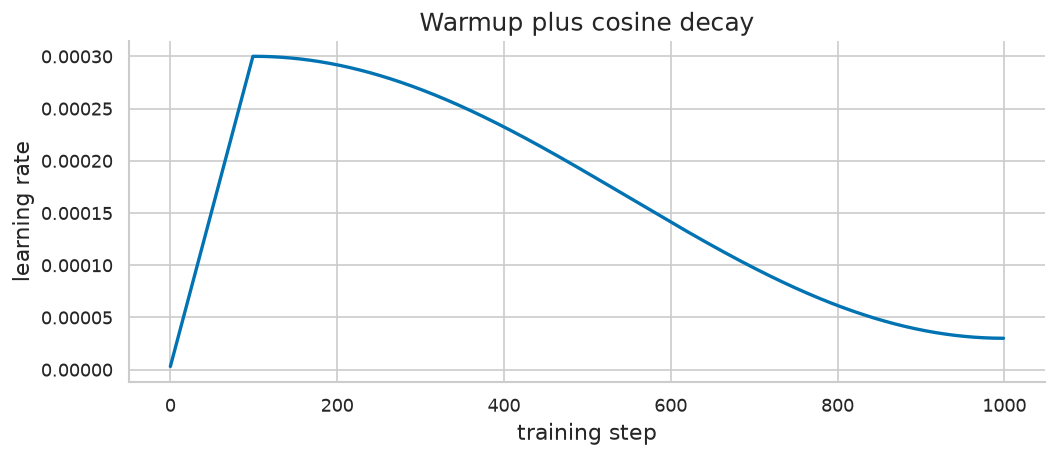

first, peak, last: 2.9999999999999997e-06 0.0003 3e-05


In [4]:
steps = np.arange(0, 1000)
warmup = 100
lr_max = 3e-4
lr_min = 3e-5

lr = np.empty_like(steps, dtype=float)
for i, step in enumerate(steps):
    if step < warmup:
        lr[i] = lr_max * (step + 1) / warmup
    else:
        s = (step - warmup) / (len(steps) - warmup - 1)
        lr[i] = lr_min + 0.5 * (lr_max - lr_min) * (1 + np.cos(np.pi * s))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(steps, lr)
ax.set_title("Warmup plus cosine decay")
ax.set_xlabel("training step")
ax.set_ylabel("learning rate")
fig.tight_layout()
plt.show()
print("first, peak, last:", lr[0], lr.max(), lr[-1])

## 4. Effective batch size

In [5]:
micro_batch = 2
sequence_length = 4096
data_parallel = 64
grad_accum = 8
tokens_per_step = micro_batch * sequence_length * data_parallel * grad_accum
print("effective sequences per optimizer step:", micro_batch * data_parallel * grad_accum)
print("tokens per optimizer step:", tokens_per_step)

effective sequences per optimizer step: 1024
tokens per optimizer step: 4194304


## 5. Memory accounting

In [6]:
P = 7e9
bytes_bf16 = 2
bytes_fp32 = 4
weights = P * bytes_bf16
grads = P * bytes_bf16
adam_moments = 2 * P * bytes_fp32
total = weights + grads + adam_moments
print("weights GB:", weights / 1e9)
print("grads GB:", grads / 1e9)
print("Adam moments GB:", adam_moments / 1e9)
print("training state GB before activations:", total / 1e9)

weights GB: 14.0
grads GB: 14.0
Adam moments GB: 56.0
training state GB before activations: 84.0


## 6. ZeRO-style sharding stages

In [7]:
world = 8
weights = 14.0
grads = 14.0
optim = 56.0

stage0 = weights + grads + optim
stage1 = weights + grads + optim / world
stage2 = weights + grads / world + optim / world
stage3 = weights / world + grads / world + optim / world

for name, gb in [("replicated", stage0), ("stage1", stage1), ("stage2", stage2), ("stage3", stage3)]:
    print(f"{name:>10s}: {gb:.2f} GB per rank before activations")

replicated: 84.00 GB per rank before activations
    stage1: 35.00 GB per rank before activations
    stage2: 22.75 GB per rank before activations
    stage3: 10.50 GB per rank before activations


## 7. Activation checkpointing tradeoff

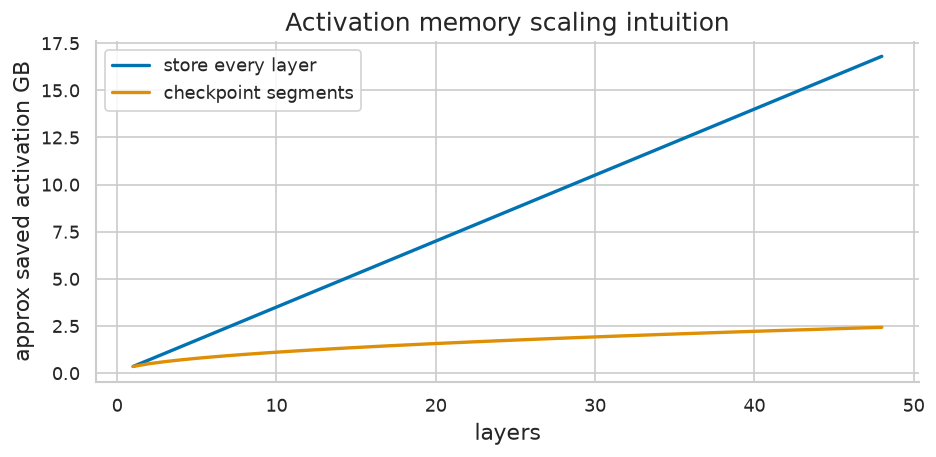

48-layer rough memory no checkpoint: 16.799999999999997
48-layer rough memory checkpointed: 2.424871130596428


In [8]:
layers = np.arange(1, 49)
activation_per_layer_gb = 0.35
saved_without = layers * activation_per_layer_gb
saved_with_segments = np.sqrt(layers) * activation_per_layer_gb

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(layers, saved_without, label="store every layer")
ax.plot(layers, saved_with_segments, label="checkpoint segments")
ax.set_title("Activation memory scaling intuition")
ax.set_xlabel("layers")
ax.set_ylabel("approx saved activation GB")
ax.legend()
fig.tight_layout()
plt.show()
print("48-layer rough memory no checkpoint:", saved_without[-1])
print("48-layer rough memory checkpointed:", saved_with_segments[-1])

## 8. Pipeline bubble

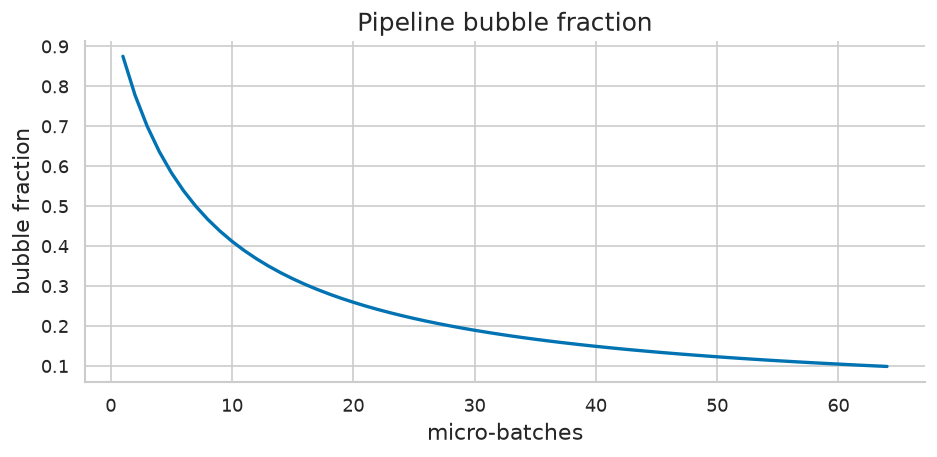

micro_batches= 1: bubble=0.875
micro_batches= 4: bubble=0.636
micro_batches=16: bubble=0.304
micro_batches=64: bubble=0.099


In [9]:
stages = 8
micro_batches = np.arange(1, 65)
bubble = (stages - 1) / (micro_batches + stages - 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(micro_batches, bubble)
ax.set_title("Pipeline bubble fraction")
ax.set_xlabel("micro-batches")
ax.set_ylabel("bubble fraction")
fig.tight_layout()
plt.show()
for m in [1, 4, 16, 64]:
    print(f"micro_batches={m:>2}: bubble={(stages-1)/(m+stages-1):.3f}")

## 9. All-reduce cost model

In [10]:
payload_gb = np.array([0.5, 1.0, 2.0, 4.0])
bandwidth_gbps = 200.0
latency_ms = 0.05
time_ms = latency_ms + payload_gb / bandwidth_gbps * 1000
for payload, ms in zip(payload_gb, time_ms):
    print(f"payload={payload:.1f} GB -> approx {ms:.2f} ms")

payload=0.5 GB -> approx 2.55 ms
payload=1.0 GB -> approx 5.05 ms
payload=2.0 GB -> approx 10.05 ms
payload=4.0 GB -> approx 20.05 ms


## 10. FLOPs and MFU

In [11]:
params = 7e9
tokens = 300e9
train_flops = 6 * params * tokens
days = 14
seconds = days * 24 * 3600
useful_flops_per_sec = train_flops / seconds
hardware_peak = 512 * 312e12
mfu = useful_flops_per_sec / hardware_peak
print("training FLOPs:", f"{train_flops:.3e}")
print("useful FLOPs/sec:", f"{useful_flops_per_sec:.3e}")
print("MFU:", round(mfu, 3))

training FLOPs: 1.260e+22
useful FLOPs/sec: 1.042e+16
MFU: 0.065


## 11. Compute-optimal tradeoff surface

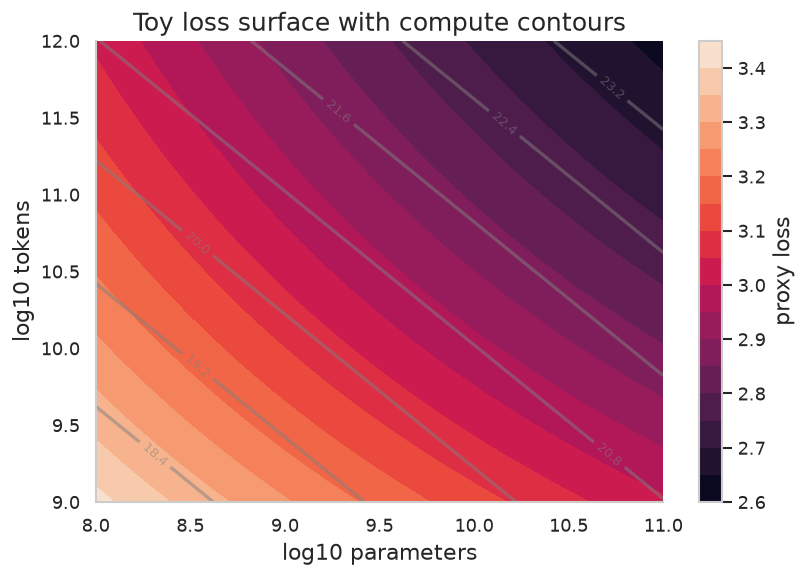

This is a teaching proxy, not an empirical scaling-law fit.


In [12]:
N = np.logspace(8, 11, 40)
D = np.logspace(9, 12, 40)
NN, DD = np.meshgrid(N, D)
compute = 6 * NN * DD
loss_proxy = 1.7 + 0.8 * (NN / 1e9) ** -0.08 + 0.6 * (DD / 1e10) ** -0.10

fig, ax = plt.subplots(figsize=(7, 5))
cs = ax.contour(np.log10(NN), np.log10(DD), np.log10(compute), levels=8, colors="gray", alpha=0.5)
im = ax.contourf(np.log10(NN), np.log10(DD), loss_proxy, levels=16)
fig.colorbar(im, ax=ax, label="proxy loss")
ax.clabel(cs, inline=True, fontsize=8)
ax.set_title("Toy loss surface with compute contours")
ax.set_xlabel("log10 parameters")
ax.set_ylabel("log10 tokens")
fig.tight_layout()
plt.show()
print("This is a teaching proxy, not an empirical scaling-law fit.")

## 12. Token packing utilization

In [13]:
lengths = np.array([128, 512, 900, 64, 256, 700, 1024, 300])
block = 1024
padded_tokens = len(lengths) * block
real_tokens = lengths.sum()
naive_util = real_tokens / padded_tokens
packed_blocks = int(np.ceil(real_tokens / block))
packed_util = real_tokens / (packed_blocks * block)
print("naive utilization:", round(naive_util, 3))
print("packed utilization:", round(packed_util, 3))

naive utilization: 0.474
packed utilization: 0.948


## 13. Checkpoint overhead

In [14]:
step_time = 2.0
checkpoint_time = 180.0
intervals = np.array([100, 500, 1000, 5000])
overhead_fraction = checkpoint_time / (intervals * step_time + checkpoint_time)
for interval, overhead in zip(intervals, overhead_fraction):
    print(f"checkpoint every {interval:>4} steps -> overhead {100*overhead:.2f}%")

checkpoint every  100 steps -> overhead 47.37%
checkpoint every  500 steps -> overhead 15.25%
checkpoint every 1000 steps -> overhead 8.26%
checkpoint every 5000 steps -> overhead 1.77%


## 14. Loss spike detection

detected spike steps: [120]


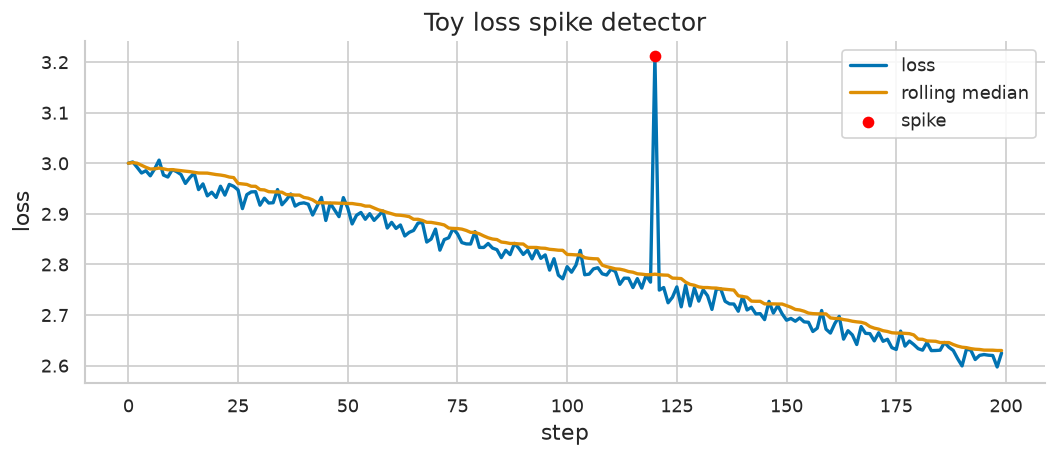

In [15]:
rng = np.random.default_rng(7)
loss = 3.0 - 0.002 * np.arange(200) + rng.normal(0, 0.015, 200)
loss[120] += 0.45
window = 20
median = np.array([np.median(loss[max(0, i-window):i+1]) for i in range(len(loss))])
spikes = np.where(loss > median + 0.20)[0]
print("detected spike steps:", spikes.tolist())

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(loss, label="loss")
ax.plot(median, label="rolling median")
ax.scatter(spikes, loss[spikes], color="red", zorder=3, label="spike")
ax.set_title("Toy loss spike detector")
ax.set_xlabel("step")
ax.set_ylabel("loss")
ax.legend()
fig.tight_layout()
plt.show()

## 15. Final launch checklist

In [16]:
checks = [
    "small run learns and resumes exactly",
    "labels are shifted and masks are tested",
    "memory estimate includes optimizer states and activations",
    "global batch and token budget are explicit",
    "parallelism product equals world size",
    "validation loss and throughput are logged separately",
    "checkpoint includes model, optimizer, scheduler, RNG, and dataloader state",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. small run learns and resumes exactly
2. labels are shifted and masks are tested
3. memory estimate includes optimizer states and activations
4. global batch and token budget are explicit
5. parallelism product equals world size
6. validation loss and throughput are logged separately
7. checkpoint includes model, optimizer, scheduler, RNG, and dataloader state


## 16. Gradient noise scale regimes (new)

Notes Section 11: compare a chosen batch to $\mathcal{B}_{noise}=\mathrm{tr}(\Sigma)/|g|^2$ at two training phases.

In [17]:
tr_sigma=4.0
for phase,g2 in [("early",1e-2),("late",1e-4)]:
    b=tr_sigma/g2; print(f"{phase}: B_noise={b:,.0f} examples-equivalent")
ok=(tr_sigma/1e-4)>(tr_sigma/1e-2)
print(f"{'PASS' if ok else 'FAIL'} - noise scale grows as gradient signal shrinks")

early: B_noise=400 examples-equivalent
late: B_noise=40,000 examples-equivalent
PASS - noise scale grows as gradient signal shrinks


## 17. Learning-rate scaling rules compared (new)

Notes Section 12: linear versus square-root scaling from a 1M-token base batch.

In [18]:
base_b,base_lr=1e6,1e-4
for mult in [1,2,4,8,16]:
    print(f"batch x{mult}: linear lr={base_lr*mult:.2e}, sqrt lr={base_lr*np.sqrt(mult):.2e}")
ok=abs(base_lr*np.sqrt(16)-4e-4)<1e-12
print(f"{'PASS' if ok else 'FAIL'} - sqrt scaling at x16 gives 4x learning rate")

batch x1: linear lr=1.00e-04, sqrt lr=1.00e-04
batch x2: linear lr=2.00e-04, sqrt lr=1.41e-04
batch x4: linear lr=4.00e-04, sqrt lr=2.00e-04
batch x8: linear lr=8.00e-04, sqrt lr=2.83e-04
batch x16: linear lr=1.60e-03, sqrt lr=4.00e-04
PASS - sqrt scaling at x16 gives 4x learning rate


## 18. ZeRO memory per device (new)

Notes 13.3/19.1: 7B model, 112 GB static state, three sharding stages.

In [19]:
total=112.0; weights=42.0; grads=14.0; adam=56.0
for world in [1,8,32]:
    s1=weights+grads+adam/world; s2=weights+grads/world+adam/world; s3=total/world
    print(f"world={world}: stage1={s1:.1f} GB, stage2={s2:.1f} GB, stage3={s3:.1f} GB")
ok=abs(total/8-14.0)<1e-9
print(f"{'PASS' if ok else 'FAIL'} - stage 3 at world 8 gives 14 GB per device")

world=1: stage1=112.0 GB, stage2=112.0 GB, stage3=112.0 GB
world=8: stage1=63.0 GB, stage2=50.8 GB, stage3=14.0 GB
world=32: stage1=57.8 GB, stage2=44.2 GB, stage3=3.5 GB
PASS - stage 3 at world 8 gives 14 GB per device


## 19. Pipeline bubble versus micro-batches, plotted (new)

Notes 5.3/36.3 with the Wong palette.

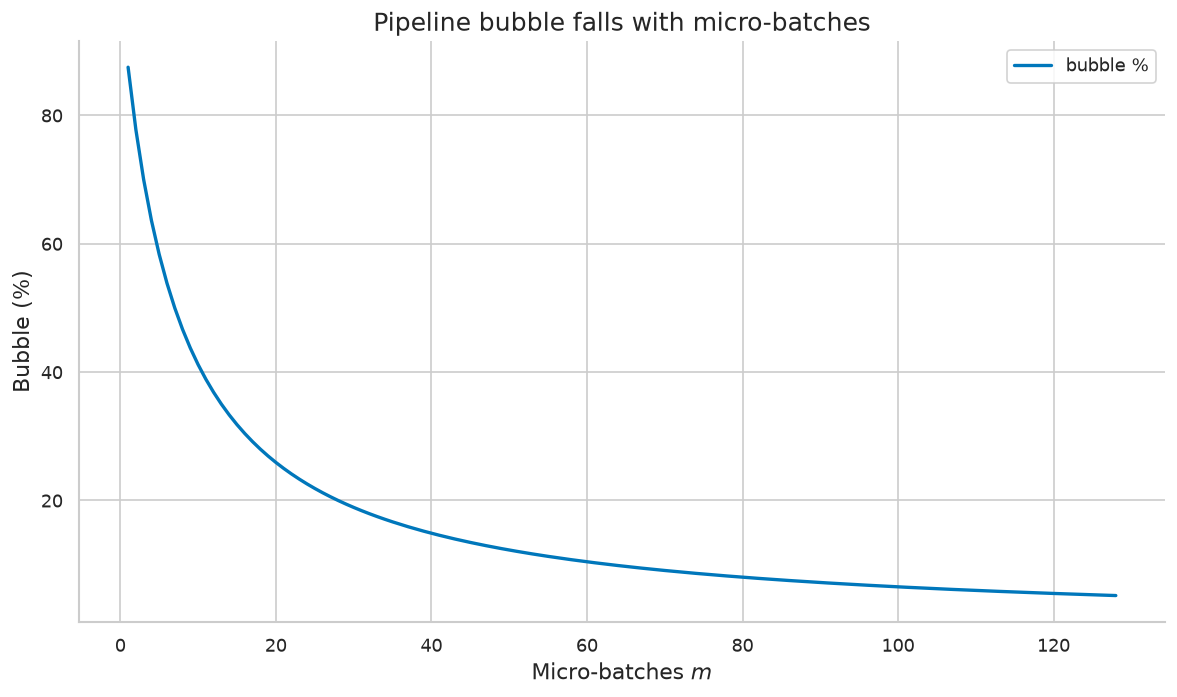

bubble at m=32: 17.9%, at m=128: 5.2%
PASS - more micro-batches reduce the bubble


In [20]:
stages=8; m=np.arange(1,129); bubble=(stages-1)/(m+stages-1)
fig, ax = plt.subplots(); ax.plot(m, bubble*100, color="#0077BB", label="bubble %")
ax.set_title("Pipeline bubble falls with micro-batches"); ax.set_xlabel("Micro-batches $m$"); ax.set_ylabel("Bubble (%)"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
print(f"bubble at m=32: {bubble[31]*100:.1f}%, at m=128: {bubble[-1]*100:.1f}%")
ok=bubble[-1]<bubble[31]
print(f"{'PASS' if ok else 'FAIL'} - more micro-batches reduce the bubble")

## 20. All-reduce time versus payload (new)

Notes 21.1/36.2: ring traffic is about $2M$ per rank at large world size.

In [21]:
payload=np.array([0.5,1.0,2.0,4.0,14.0]); bw=25.0; times=2*payload/bw
for m,t in zip(payload,times): print(f"payload {m:.1f} GB -> {t:.2f} s unoverlapped")
ok=abs(times[-1]-1.12)<1e-9
print(f"{'PASS' if ok else 'FAIL'} - 14 GB gradient costs about 1.12 s unoverlapped")

payload 0.5 GB -> 0.04 s unoverlapped
payload 1.0 GB -> 0.08 s unoverlapped
payload 2.0 GB -> 0.16 s unoverlapped
payload 4.0 GB -> 0.32 s unoverlapped
payload 14.0 GB -> 1.12 s unoverlapped
PASS - 14 GB gradient costs about 1.12 s unoverlapped


## 21. Young's checkpoint interval (new)

Notes 15.2/36.4: $\sqrt{2C\mu}$ for several job MTBF values, plotted.

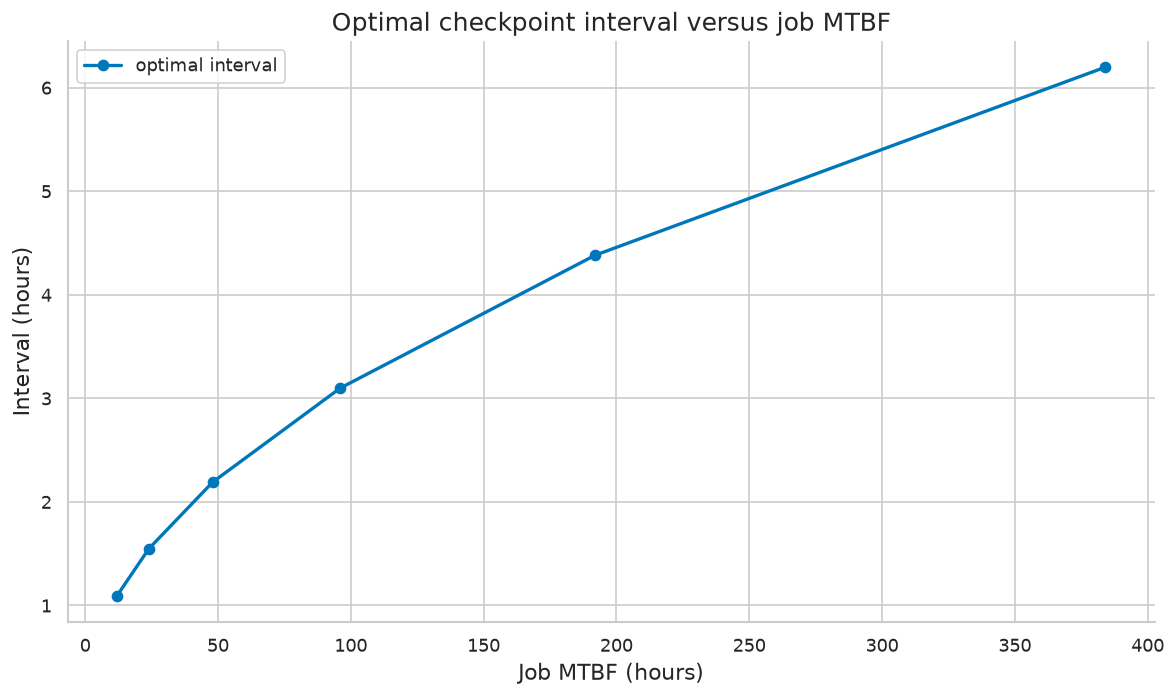

intervals (h): [1.1  1.55 2.19 3.1  4.38 6.2 ]
PASS - interval grows with reliability, as a square root


In [22]:
C=180.0; mtbf_h=np.array([12,24,48,96,192,384]); intervals=np.sqrt(2*C*mtbf_h*3600)/3600
fig, ax = plt.subplots(); ax.plot(mtbf_h, intervals, color="#0077BB", marker="o", label="optimal interval")
ax.set_title("Optimal checkpoint interval versus job MTBF"); ax.set_xlabel("Job MTBF (hours)"); ax.set_ylabel("Interval (hours)"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
print("intervals (h):", np.round(intervals,2))
ok=np.all(np.diff(intervals)>0)
print(f"{'PASS' if ok else 'FAIL'} - interval grows with reliability, as a square root")

## 22. Failure-free probability over a day (new)

Notes 15.1: $e^{-NT/M}$ falls quickly with device count $N$.

In [23]:
M=50000.0
for n in [8,64,256,1024,4096]:
    print(f"N={n}: P(no failure in 24h)={np.exp(-n*24/M):.3f}")
ok=np.exp(-1024*24/M)<0.65
print(f"{'PASS' if ok else 'FAIL'} - at 1024 devices a failure-free day is not the expected case")

N=8: P(no failure in 24h)=0.996
N=64: P(no failure in 24h)=0.970
N=256: P(no failure in 24h)=0.884
N=1024: P(no failure in 24h)=0.612
N=4096: P(no failure in 24h)=0.140
PASS - at 1024 devices a failure-free day is not the expected case


## 23. Packing efficiency on the notes example (new)

Notes 22.2: the same eight document lengths, naive versus greedy packing into 1024-token blocks.

In [24]:
lengths=np.array([128,512,900,64,256,700,1024,300]); block=1024
naive=len(lengths)*block; real=int(lengths.sum())
bins=[]
for L in sorted(lengths, reverse=True):
    placed=False
    for b in bins:
        if b+L<=block: b+=L; placed=True; break
    if not placed: bins.append(L)
# recompute bins correctly with mutable list
bins=[]
for L in sorted(lengths, reverse=True):
    for i in range(len(bins)):
        if bins[i]+L<=block: bins[i]+=L; break
    else: bins.append(L)
greedy=len(bins)*block
print(f"real={real}, naive padded={naive} ({real/naive:.1%}), greedy blocks={len(bins)} ({real/greedy:.1%})")
ok=real/greedy>real/naive
print(f"{'PASS' if ok else 'FAIL'} - greedy packing beats one-document-per-block")

real=3884, naive padded=8192 (47.4%), greedy blocks=4 (94.8%)
PASS - greedy packing beats one-document-per-block


## 24. Adam trace saturation (new)

Notes 30: with a constant gradient, Adam's update size saturates near the learning rate after bias correction.

In [25]:
theta,m,v=1.5,0.0,0.0; g=0.30; sizes=[]
for t in range(1,21):
    m=0.9*m+0.1*g; v=0.999*v+0.001*g*g; mh=m/(1-0.9**t); vh=v/(1-0.999**t); sizes.append(1e-3*mh/(np.sqrt(vh)+1e-8))
print("first sizes:", np.round(sizes[:3],6), "last:", round(float(sizes[-1]),6))
ok=abs(sizes[-1]-1e-3)<1e-4
print(f"{'PASS' if ok else 'FAIL'} - Adam step size saturates near eta for constant gradient")

first sizes: [0.001 0.001 0.001] last: 0.001
PASS - Adam step size saturates near eta for constant gradient


## 25. Scaling-law napkin fit (new)

Notes 40: an illustrative power law $L(C)$; equal compute ratios give similar absolute drops.

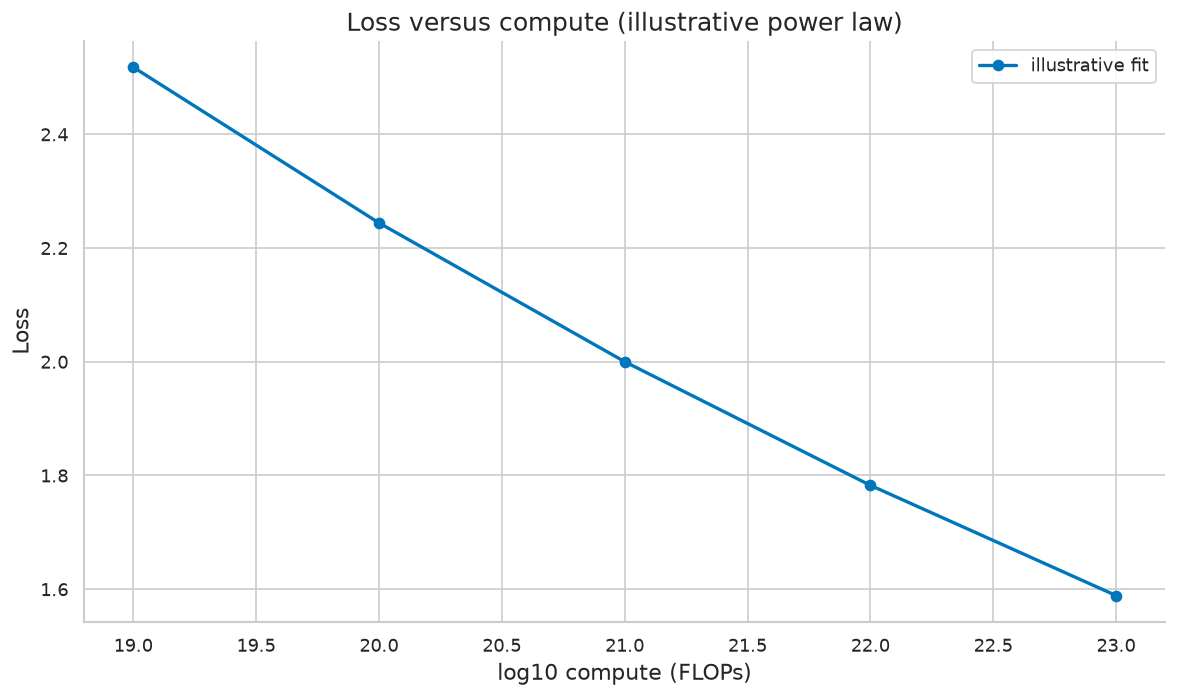

losses: [2.518 2.244 2.    1.783 1.589] drops per 10x: [0.274 0.244 0.217 0.194]
PASS - loss decreases as a power law in compute


In [26]:
C=np.array([1e19,1e20,1e21,1e22,1e23]); L=2.0*(1e21/C)**0.05
fig, ax = plt.subplots(); ax.plot(np.log10(C), L, color="#0077BB", marker="o", label="illustrative fit")
ax.set_title("Loss versus compute (illustrative power law)"); ax.set_xlabel("log10 compute (FLOPs)"); ax.set_ylabel("Loss"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
drops=np.round(-np.diff(L),3); print("losses:", np.round(L,3), "drops per 10x:", drops)
ok=np.all(np.diff(L)<0)
print(f"{'PASS' if ok else 'FAIL'} - loss decreases as a power law in compute")